|<h2>Course:</h2>|<h1><a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">A deep understanding of AI language model mechanisms</a></h1>|
|-|:-:|
|<h2>Part 1:</h2>|<h1>Tokenizations and embeddings<h1>|
|<h2>Section:</h2>|<h1>Embedding spaces<h1>|
|<h2>Lecture:</h2>|<h1><b>CodeChallenge: Math with tokens and embeddings<b></h1>|

<br>

<h5><b>Teacher:</b> Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h5>
<h5><b>Course URL:</b> <a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">udemy.com/course/dullms_x/?couponCode=202508</a></h5>
<i>Using the code without the course may lead to confusion or errors.</i>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# highres plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Import GPT-2 model and extract its embeddings matrix

In [3]:
from transformers import GPT2Model,GPT2Tokenizer

# pretrained GPT-2 model and tokenizer
gpt2 = GPT2Model.from_pretrained('gpt2')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

# extract embeddings matrix from the gpt2 model
embeddings = gpt2.wte.weight.detach().numpy()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

# Exercise 1: Numbers to tokens

In [4]:
# create some numbers
numbers = np.arange(11)
numbers = np.concatenate((numbers, 10*numbers[2:], 100*numbers[2:]), axis=0)

# initialize token vector
numTokenLabels = np.zeros(len(numbers), dtype=int)

# get and report the tokens
for i,n in enumerate(numbers):

  # get the first token for this number
  numTokenLabels[i] = tokenizer.encode(str(n))[0]

  # also try diving the number by 2!
  print(f'The number {n/2} is token(s) {tokenizer.encode(str(n/2))}')
print(f'The number {1024} is token(s) {tokenizer.encode(str(1024))}')
print(f'The number {1025} is token(s) {tokenizer.encode(str(1025))}')

The number 0.0 is token(s) [15, 13, 15]
The number 0.5 is token(s) [15, 13, 20]
The number 1.0 is token(s) [16, 13, 15]
The number 1.5 is token(s) [16, 13, 20]
The number 2.0 is token(s) [17, 13, 15]
The number 2.5 is token(s) [17, 13, 20]
The number 3.0 is token(s) [18, 13, 15]
The number 3.5 is token(s) [18, 13, 20]
The number 4.0 is token(s) [19, 13, 15]
The number 4.5 is token(s) [19, 13, 20]
The number 5.0 is token(s) [20, 13, 15]
The number 10.0 is token(s) [940, 13, 15]
The number 15.0 is token(s) [1314, 13, 15]
The number 20.0 is token(s) [1238, 13, 15]
The number 25.0 is token(s) [1495, 13, 15]
The number 30.0 is token(s) [1270, 13, 15]
The number 35.0 is token(s) [2327, 13, 15]
The number 40.0 is token(s) [1821, 13, 15]
The number 45.0 is token(s) [2231, 13, 15]
The number 50.0 is token(s) [1120, 13, 15]
The number 100.0 is token(s) [3064, 13, 15]
The number 150.0 is token(s) [8628, 13, 15]
The number 200.0 is token(s) [2167, 13, 15]
The number 250.0 is token(s) [9031, 13, 15

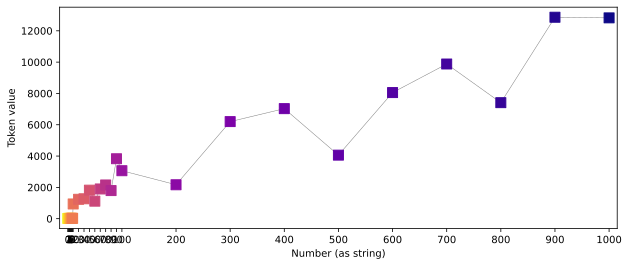

In [5]:
plt.figure(figsize=(10,4))
plt.plot(numbers, numTokenLabels, color=[.5,.5,.5], linewidth=.5)
plt.scatter(numbers, numTokenLabels, c=np.arange(len(numbers)), s=100, marker='s', cmap='plasma_r', zorder=10)

plt.gca().set(xlabel='Number (as string)',ylabel='Token value',xticks=numbers,xlim=[numbers[0]-15,numbers[-1]+15])
# plt.gca().set(xscale='log')
plt.show()

# Exercise 2: How long are numbers?

In [6]:
# tokenize integers and floating-point numbers

# initialize
numnums = 99_999
int_toklens = np.zeros(numnums, dtype=int)
float_toklens = np.zeros(numnums, dtype=int)

# random numbers
ra = 5*np.random.randn(numnums)

for i in range(numnums):

  # integers
  int_toklens[i] = len(tokenizer.encode(str(i)))

  # and the random numbers
  float_toklens[i] = len(tokenizer.encode(str(ra[i])))

In [7]:
_,axs = plt.subplots(1,2,figsize=(12,4))

axs[0].plot(int_toklens,'s',markerfacecolor=[.7,.7,.9],alpha=.4)
axs[1].plot(ra, float_toklens,'o',markerfacecolor=[.7,.9,.7],alpha=.4)

axs[0].set(xlabel='Number',ylabel='Token length',yticks=range(int_toklens.max()+2),title='Token lengths of integers')
axs[1].set(xlabel='Number',ylabel='Token length',title='Token lengths of floating-point numbers')

plt.tight_layout()
plt.show()

# Exercise 3: Does math work in token conversions?

In [ ]:
# the equation and its tokens


# try the math


In [8]:
# maybe just the numbers?
t5 = tokenizer.encode('5')
t3 = tokenizer.encode('3')

# let's see...


# Exercise 4: How about embeddings?

Embedding vector for 5: [-1.09711394e-01  2.47270502e-02  1.84050590e-01 -6.73095956e-02
  1.04933791e-02 -4.10528257e-02 -2.18655556e-01 -1.33332700e-01
 -5.25880866e-02 -3.66746001e-02  4.00302671e-02 -5.53697124e-02
  3.57819721e-02 -1.10381521e-01  6.23035878e-02 -9.44289416e-02
  1.75444379e-01  1.30085707e-01  1.27251372e-01  1.12061523e-01
 -7.51352087e-02  3.49194780e-02  9.03071910e-02  1.29904002e-01
 -5.20913415e-02  1.52840719e-01 -7.54343439e-03 -4.13916893e-02
 -1.51989665e-02 -2.46041268e-02  7.43257776e-02  1.45155960e-03
 -5.26606280e-04 -1.47668675e-01 -1.13117574e-02 -9.23479162e-03
 -3.19335908e-01  6.32823631e-02 -4.32854258e-02 -1.17531419e-01
  1.72329340e-02 -1.48282722e-01  2.78123282e-02 -1.08265713e-01
  1.42865077e-01 -1.00123152e-01 -1.45044133e-01  1.31582931e-01
 -6.56807944e-02 -1.70564562e-01  5.41049652e-02 -6.96122572e-02
  1.67219490e-01  4.08895081e-03  5.69433011e-02 -1.76012307e-01
  6.85000909e-04  1.04828551e-01 -1.62929483e-02 -1.43965455e-02
 

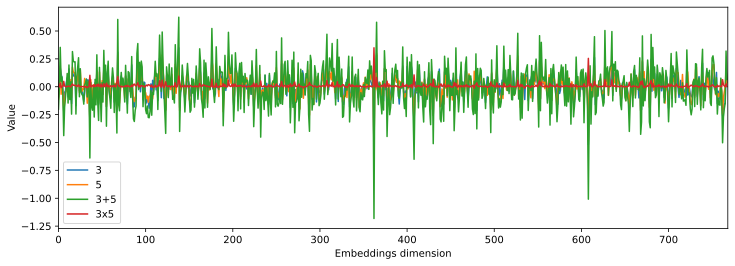

In [9]:
# isolate the embedding vectors
e5 = embeddings[t5,:].squeeze()
e3 = embeddings[t3,:].squeeze()
print(f'Embedding vector for 5: {e5}')
print(f'Embedding vector for 3: {e3}')

# math
theirSum = e3 + e5
theirProd = e3 * e5

# plot the vectors
plt.figure(figsize=(12,4))

plt.plot(e3,label='3')
plt.plot(e5,label='5')
plt.plot(theirSum,label='3+5')
plt.plot(theirProd,label='3x5')

plt.gca().set(xlabel='Embeddings dimension',ylabel='Value',xlim=[0,len(e3)])
plt.legend()
plt.show()

In [10]:
# unembedding as transpose of embeddings
sumUnembedding  = theirSum @ embeddings.T
prodUnembedding = theirProd @ embeddings.T

# print sizes
print(f'Summed vector X embeddings matrix = unembeddings vector')


# find the argmax output
print(f'Max embedding of 5+3 = "{tokenizer.decode(np.argmax(sumUnembedding))}"')
print(f'Max embedding of 5x3 = "{tokenizer.decode(np.argmax(prodUnembedding))}"')

Summed vector X embeddings matrix = unembeddings vector
Max embedding of 5+3 = "5"
Max embedding of 5x3 = " Weinstein"


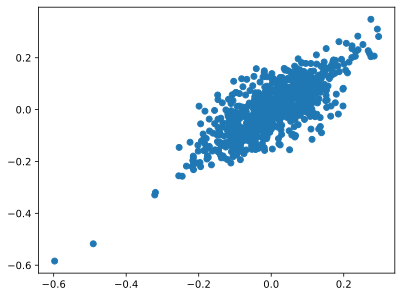

In [11]:
# curious to see how the embeddings for '3' and '5' compare
plt.plot(e5, e3, 'o')
plt.show()